<a href="https://colab.research.google.com/github/vtu27065/Deep-Learning/blob/main/Untitle%20Task%209%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

OpenCV version: 4.14.0
Face detection model loaded successfully.
Image loaded successfully: (512, 512, 3)


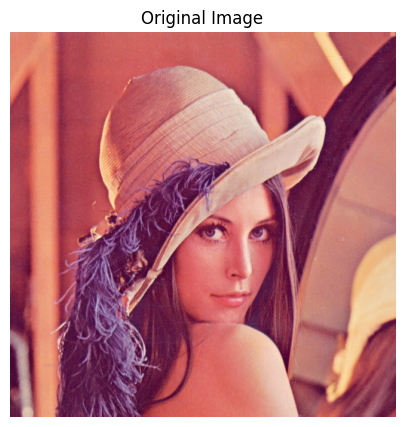

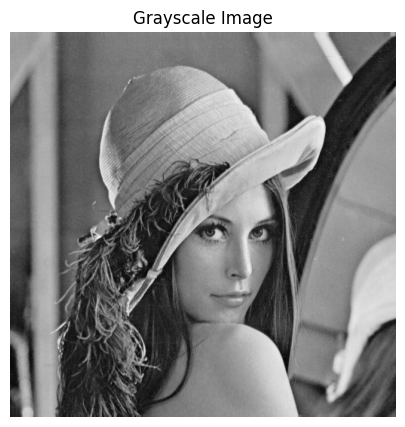

Number of faces detected: 1
Bounding boxes (x, y, width, height):
[219 203 169 169]


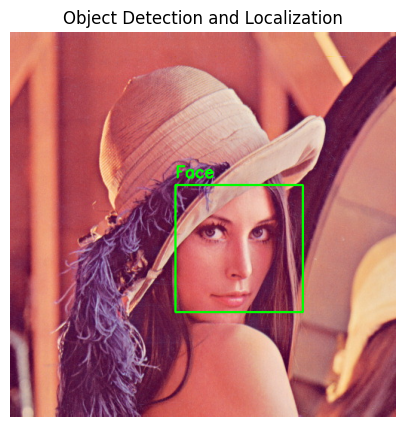

Object 1: x=219, y=203, width=169, height=169
Object detection and localization using OpenCV completed.
The green rectangles show the detected face locations.


In [2]:
# Step 1: Import the required libraries
# Code cell 3
# Cell 3 of 20

import cv2
import matplotlib.pyplot as plt
import urllib.request
import numpy as np
from IPython.display import display, Image

print("OpenCV version:", cv2.__version__)

# Step 2: Load the pre-trained face detection model
# Cell 4 of 20
# Step 2: Load the pre-trained face detection model
# Code cell 5
# Cell 5 of 20

# OpenCV includes a Haar Cascade face detector.
cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
face_cascade = cv2.CascadeClassifier(cascade_path)

if face_cascade.empty():
    raise RuntimeError("Could not load the Haar Cascade model.")

print("Face detection model loaded successfully.")

# Step 3: Load a sample image
# Cell 6 of 20
# Step 3: Load a sample image
# Code cell 7
# Cell 7 of 20

# Download a public sample image for the demonstration.
image_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
image_path = "sample_image.jpg"

try:
    urllib.request.urlretrieve(image_url, image_path)
    image = cv2.imread(image_path)
    if image is None:
        raise RuntimeError("Image could not be read.")
    print("Image loaded successfully:", image.shape)
except Exception as error:
    print("Could not download the sample image.")
    print("Upload your own image and replace the image-loading code with:")
    print("image = cv2.imread('/content/your_image.jpg')")
    raise error

# Step 4: Display the original image
# Cell 8 of 20
# Step 4: Display the original image
# Code cell 9
# Cell 9 of 20

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 5))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

# Step 5: Convert the image to grayscale
# Cell 10 of 20
# Step 5: Convert the image to grayscale
# Code cell 11
# Cell 11 of 20

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(7, 5))
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

# Step 6: Detect objects (faces) in the image
# Cell 12 of 20
# Step 6: Detect objects (faces) in the image
# Code cell 13
# Cell 13 of 20

faces = face_cascade.detectMultiScale(
    gray_image,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

print("Number of faces detected:", len(faces))
print("Bounding boxes (x, y, width, height):")
for box in faces:
    print(box)

# Step 7: Localize detected objects with bounding boxes
# Cell 14 of 20
# Step 7: Localize detected objects with bounding boxes
# Code cell 15
# Cell 15 of 20

output_image = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(output_image, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(
        output_image,
        "Face",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )

output_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 5))
plt.imshow(output_rgb)
plt.title("Object Detection and Localization")
plt.axis("off")
plt.show()

# Step 8: Print the localization results
# Cell 16 of 20
# Step 8: Print the localization results
# Code cell 17
# Cell 17 of 20

if len(faces) > 0:
    for i, (x, y, w, h) in enumerate(faces, start=1):
        print(f"Object {i}: x={x}, y={y}, width={w}, height={h}")
else:
    print("No faces were detected in the image.")

# Step 9: Result
# Cell 18 of 20
# Step 9: Result
# Code cell 19
# Cell 19 of 20

print("Object detection and localization using OpenCV completed.")
print("The green rectangles show the detected face locations.")